In [1]:
from Bio import SeqIO
import numpy as np
import pandas as pd
from collections import Counter
import matplotlib.pyplot as plt
import json
from pathlib import Path
from sklearn.model_selection import train_test_split

# Paths configured by AI
project_root = Path('..')
file_path = project_root / 'data' / 'raw' / 'deeploc_data.fasta'
aa_to_idx_path = project_root / 'configs' / 'aa_to_idx.json'
label_to_idx_path = project_root / 'configs' / 'label_to_idx.json'
train_data_path = project_root / 'data' / 'clean' / 'deeploc_train.csv'
val_data_path = project_root / 'data' / 'clean' / 'deeploc_val.csv'
test_data_path = project_root / 'data' / 'clean' / 'deeploc_test.csv'

In [2]:
# Author: Dhruv

proteins = []
file_type = 'fasta'
for protein in SeqIO.parse(file_path, file_type):
    protein_seq = str(protein.seq)

    # header
    header = protein.description

    proteins.append({
        "protein_id": protein.id,
        "sequence": protein_seq,
        "header": header
    })

df = pd.DataFrame(proteins)
print(df.head())

  protein_id                                           sequence  \
0     Q9H400  MGLPVSWAPPALWVLGCCALLLSLWALCTACRRPEDAVAPRKRARR...   
1     Q5I0E9  MEVLEEPAPGPGGADAAERRGLRRLLLSGFQEELRALLVLAGPAFL...   
2     P63033  MMKTLSSGNCTLNVPAKNSYRMVVLGASRVGKSSIVSRFLNGRFED...   
3     Q9NR71  MAKRTFSNLETFLIFLLVMMSAITVALLSLLFITSGTIENHKDLGG...   
4     Q86XT9  MGNCQAGHNLHLCLAHHPPLVCATLILLLLGLSGLGLGSFLLTHRT...   

                        header  
0  Q9H400 Cell.membrane-M test  
1       Q5I0E9 Cell.membrane-M  
2       P63033 Cell.membrane-M  
3       Q9NR71 Cell.membrane-M  
4       Q86XT9 Cell.membrane-M  


In [3]:
# Author: Dhruv
def parse_header(header):
    '''
    Extract the subcellular location (output label), membrane_status, and train/test label from the header
    Args:
        header(str): header for row
    Returns:
        Tuple of subcellular loc, membrane status, and train test label

    '''
    header_parts = header.split()

    subcellular_location = header_parts[1][:-2]
    membrane_status = header_parts[1][-1]

    if len(header_parts) > 2:
        train_test = header_parts[2]
    else:
        train_test = 'train'
    
    return (subcellular_location, membrane_status, train_test)

new_cols = df['header'].apply(parse_header).apply(pd.Series)
df[['subcellular_location', 'membrane_status', 'train_test']] = new_cols

# drop headers column: info has been parsed into new cols
df.drop(columns=['header'], inplace=True)

print(df.head())

  protein_id                                           sequence  \
0     Q9H400  MGLPVSWAPPALWVLGCCALLLSLWALCTACRRPEDAVAPRKRARR...   
1     Q5I0E9  MEVLEEPAPGPGGADAAERRGLRRLLLSGFQEELRALLVLAGPAFL...   
2     P63033  MMKTLSSGNCTLNVPAKNSYRMVVLGASRVGKSSIVSRFLNGRFED...   
3     Q9NR71  MAKRTFSNLETFLIFLLVMMSAITVALLSLLFITSGTIENHKDLGG...   
4     Q86XT9  MGNCQAGHNLHLCLAHHPPLVCATLILLLLGLSGLGLGSFLLTHRT...   

  subcellular_location membrane_status train_test  
0        Cell.membrane               M       test  
1        Cell.membrane               M      train  
2        Cell.membrane               M      train  
3        Cell.membrane               M      train  
4        Cell.membrane               M      train  


In [4]:
df['train_test'].value_counts()

train_test
train    11231
test      2773
Name: count, dtype: int64

In [5]:
# check missing values
print(df.isnull().sum())
# check duplicates
print("Duplicate IDs:", df['protein_id'].duplicated().sum())
print("Duplicate sequences:", df['sequence'].duplicated().sum())

protein_id              0
sequence                0
subcellular_location    0
membrane_status         0
train_test              0
dtype: int64
Duplicate IDs: 0
Duplicate sequences: 55


In [6]:
# Author: Dhruv

# check unusual amino acids
usual_amino_acids = set("ACDEFGHIKLMNPQRSTVWY")
unusual_amino_acids = set("XBZUOJ")

# check if a sequence contains unusual amino acids
def count_unusual(seq):
    count = 0
    for aa in seq:
        if aa in unusual_amino_acids:
            count += 1
    return count

df['num_unusual_aa'] = df['sequence'].apply(count_unusual)
print((df['num_unusual_aa'] > 0).sum())

34


In [7]:
# Author: Dhruv

unusual_rows = df[df['num_unusual_aa'] > 0]

counts = Counter()

for seq in unusual_rows['sequence']:
    for aa in seq:
        if aa in unusual_amino_acids:
            counts[aa] += 1

print(counts)

Counter({'X': 76, 'U': 30, 'Z': 4, 'B': 2})


In [8]:
# Author: Dhruv

# standard amino acids
amino_acids = "ACDEFGHIKLMNPQRSTVWY"
aa_to_idx = {'PAD': 0}

for i, aa in enumerate(amino_acids):
    aa_to_idx[aa] = i + 1

# unknown amino acids
aa_to_idx['UNK'] = 21

for aa in "XBZUOJ":
    aa_to_idx[aa] = aa_to_idx["UNK"]

In [9]:
# Author: Dhruv

# check variation in sequence lengths
df['seq_length'] = df['sequence'].str.len()
print(df['seq_length'].describe())

count    14004.00000
mean       522.44166
std        448.06671
min         40.00000
25%        249.00000
50%        421.00000
75%        649.00000
max      13100.00000
Name: seq_length, dtype: float64


In [10]:
# Author: Dhruv

# inspect duplicates
duplicates = df[df.duplicated('sequence', keep=False)]
duplicates = duplicates.sort_values('sequence')
print(f"duplicate labels: {duplicates['train_test'].value_counts()}")

print(duplicates[['protein_id', 'subcellular_location', 'membrane_status', 'train_test']])

cols = ['subcellular_location', 'membrane_status']

# check which duplicates have mismatch data: potential problem
conflicts = df.groupby('sequence')[cols].nunique()
conflicting_sequences = conflicts[(conflicts > 1).any(axis=1)]

# retreive df rows of duplicates
conflicting_rows = df[df['sequence'].isin(conflicting_sequences.index)]

print(conflicting_rows[['protein_id', 'subcellular_location', 'membrane_status', 'train_test']])

duplicate labels: train_test
train    95
test     10
Name: count, dtype: int64
      protein_id subcellular_location membrane_status train_test
11674     P68164              Plastid               U      train
11675     P68163              Plastid               U      train
13583     P0C892        Extracellular               S      train
13018     Q86QV0        Extracellular               S      train
13898     P83288        Extracellular               S      train
...          ...                  ...             ...        ...
1628      P0CX27            Cytoplasm               S      train
13421     Q25619        Extracellular               S      train
13962     Q8WT57        Extracellular               S      train
13008     P85174        Extracellular               S      train
13654     P85436        Extracellular               S      train

[105 rows x 4 columns]
Empty DataFrame
Columns: [protein_id, subcellular_location, membrane_status, train_test]
Index: []


In [11]:
# Author: Dhruv

# separate train and test dataframes
train_df = df[df['train_test'] == 'train'].copy()
test_df = df[df['train_test'] == 'test'].copy()

# remove duplicates from training data
train_df = train_df.drop_duplicates(subset='sequence')

# train and test dataset sizes
print("Training set size:", len(train_df))
print("Test set size:", len(test_df))
train_percent = 100 * len(train_df) / len(df)
test_percent = 100 * len(test_df) / len(df)
print("Train/Test Split:", train_percent, ':', test_percent)

Training set size: 11181
Test set size: 2773
Train/Test Split: 79.84147386461011 : 19.801485289917167


In [12]:
train_df.head()

,protein_id,sequence,subcellular_location,membrane_status,train_test,num_unusual_aa,seq_length
1,Q5I0E9,MEVLEEPAPGPGGADAAERRGLRRLLLSGFQEELRALLVLAGPAFL...,Cell.membrane,M,train,0,566
2,P63033,MMKTLSSGNCTLNVPAKNSYRMVVLGASRVGKSSIVSRFLNGRFED...,Cell.membrane,M,train,0,266
3,Q9NR71,MAKRTFSNLETFLIFLLVMMSAITVALLSLLFITSGTIENHKDLGG...,Cell.membrane,M,train,0,780
4,Q86XT9,MGNCQAGHNLHLCLAHHPPLVCATLILLLLGLSGLGLGSFLLTHRT...,Cell.membrane,M,train,0,240
5,A2CI98,MDPSKQGTLNRVENSVYRTAFKLRSVQTLCQLDLMDSFLIQQVLWR...,Cell.membrane,M,train,0,653


In [13]:
test_df.head()

,protein_id,sequence,subcellular_location,membrane_status,train_test,num_unusual_aa,seq_length
0,Q9H400,MGLPVSWAPPALWVLGCCALLLSLWALCTACRRPEDAVAPRKRARR...,Cell.membrane,M,test,0,295
9,P83456,AGFPEQEPEPKFWNDWAQKTLDKALSLQTLNKNKAQNLILFLGDGM...,Cell.membrane,M,test,0,477
15,Q9GL77,MEDEAVLDRGASFLKHVCDEEEVEGHHTIYIGVHVPKSYRRRRRHK...,Cell.membrane,M,test,0,1079
20,Q03445,MHSRLKFLAYLHFICASSIFWPEFSSAQQQQQTVSLTEKIPLGAIF...,Cell.membrane,M,test,0,991
23,P35525,MAAATAAAATVAGEGMEPRALQYEQTLMYGRYTQELGAFAKEEAAR...,Cell.membrane,M,test,0,907


In [14]:
# inspect output class balance

print(train_df["subcellular_location"].value_counts())
print(train_df["subcellular_location"].value_counts(normalize=True))

subcellular_location
Nucleus                  3228
Cytoplasm                2016
Extracellular            1565
Mitochondrion            1203
Cell.membrane            1067
Endoplasmic.reticulum     689
Plastid                   602
Golgi.apparatus           286
Lysosome/Vacuole          256
Cytoplasm-Nucleus         145
Peroxisome                124
Name: count, dtype: int64
subcellular_location
Nucleus                  0.288704
Cytoplasm                0.180306
Extracellular            0.139970
Mitochondrion            0.107593
Cell.membrane            0.095430
Endoplasmic.reticulum    0.061622
Plastid                  0.053841
Golgi.apparatus          0.025579
Lysosome/Vacuole         0.022896
Cytoplasm-Nucleus        0.012968
Peroxisome               0.011090
Name: proportion, dtype: float64


In [15]:
# Author: Dhruv

# split the training data into true training set and validation set, leaving the test set untouched

train_df, val_df = train_test_split(
    train_df,
    test_size=0.1,
    random_state=42,
    stratify=train_df["subcellular_location"]
)

In [16]:
# Author: AI

# check duplicates within each dataset
print("Train duplicates:", train_df['sequence'].duplicated().sum())
print("Validation duplicates:", val_df['sequence'].duplicated().sum())
print("Test duplicates:", test_df['sequence'].duplicated().sum())

# check sequence overlap between datasets
train_seqs = set(train_df['sequence'])
val_seqs = set(val_df['sequence'])
test_seqs = set(test_df['sequence'])

print("Train/Val overlap:", len(train_seqs & val_seqs))
print("Train/Test overlap:", len(train_seqs & test_seqs))
print("Val/Test overlap:", len(val_seqs & test_seqs))

Train duplicates: 0
Validation duplicates: 0
Test duplicates: 5
Train/Val overlap: 0
Train/Test overlap: 0
Val/Test overlap: 0


In [17]:
# Author: AI

# check duplicates in test set
test_duplicates = test_df[test_df['sequence'].duplicated(keep=False)]
print(test_duplicates[['protein_id', 'subcellular_location', 'membrane_status']])

conflicts = test_df.groupby('sequence')[['subcellular_location', 'membrane_status']].nunique()
print(conflicts[(conflicts > 1).any(axis=1)])

# don't want to change test set at all because it should be the same as DeepLoc's test set which we will use as a bench mark

     protein_id subcellular_location membrane_status
1662     P0CX83            Cytoplasm               S
2801     P0CX82            Cytoplasm               S
3412     P0CX85            Cytoplasm               S
3413     P0CX84            Cytoplasm               S
3970     P0CX32            Cytoplasm               S
3973     P0CX31            Cytoplasm               S
7236     Q3C1E9              Nucleus               U
7389     Q9Y294              Nucleus               U
7471     P61965              Nucleus               U
7814     P61964              Nucleus               U
Empty DataFrame
Columns: [subcellular_location, membrane_status]
Index: []


In [18]:
# check lengths
print(len(train_df))
print(len(val_df))
print(len(test_df))

10062
1119
2773


In [19]:
# summarize sequence lengths by localization
length_stats = train_df.groupby('subcellular_location')['seq_length'].agg(['count', 'mean', 'median', 'std', 'min', 'max'])

print(length_stats.sort_values('median'))

                       count        mean  median         std  min    max
subcellular_location                                                    
Extracellular           1408  296.102273   150.0  495.875898   40  13100
Mitochondrion           1083  380.896584   338.0  245.974640   51   2628
Plastid                  542  440.132841   396.0  255.477222   64   2208
Peroxisome               112  441.258929   399.5  208.072222   51   1742
Endoplasmic.reticulum    620  480.293548   416.5  319.058704   68   2754
Golgi.apparatus          257  527.108949   455.0  336.061279   70   2779
Cytoplasm               1814  628.443219   480.0  530.419350   58   6620
Lysosome/Vacuole         230  520.421739   484.0  363.727597   99   3619
Nucleus                 2905  609.932186   489.0  481.128753   48   5596
Cytoplasm-Nucleus        131  566.610687   520.0  332.398292  106   2549
Cell.membrane            960  604.304167   520.5  365.501799   69   3579


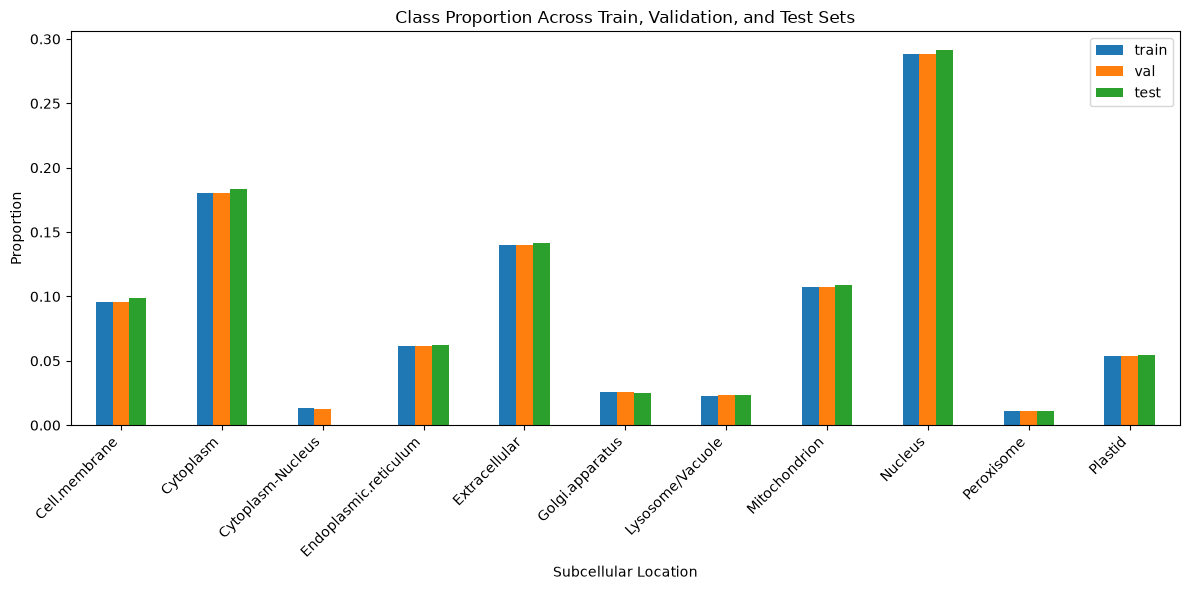

In [20]:
# Author: AI

# compare output class proportions of each dataset split 

train_props = train_df['subcellular_location'].value_counts(normalize=True)
val_props = val_df['subcellular_location'].value_counts(normalize=True)
test_props = test_df['subcellular_location'].value_counts(normalize=True)

props_df = pd.DataFrame({
    'train': train_props,
    'val': val_props,
    'test': test_props
}).fillna(0)

props_df = props_df.sort_index()

props_df.plot(kind='bar', figsize=(12, 6))
plt.xlabel('Subcellular Location')
plt.ylabel('Proportion')
plt.title('Class Proportion Across Train, Validation, and Test Sets')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [21]:
test_df['subcellular_location'].value_counts().get('Cytoplasm-Nucleus', 0)

0

In [22]:
# Author: Dhruv

# omit Cytoplasm-Nucleus from training and validation data since it is not included in the predetermined test set

train_df = train_df[train_df['subcellular_location'] != 'Cytoplasm-Nucleus'].copy()

val_df = val_df[val_df['subcellular_location'] != 'Cytoplasm-Nucleus'].copy()

In [23]:
# Author: Dhruv

# subcellular localization labels
classes = sorted(train_df['subcellular_location'].unique())

label_to_idx = {}

for i in range(len(classes)):
    label_to_idx[classes[i]] = i

train_df['label'] = train_df['subcellular_location'].map(label_to_idx)
val_df['label'] = val_df['subcellular_location'].map(label_to_idx)
test_df['label'] = test_df['subcellular_location'].map(label_to_idx)

# check labels were encoded
print(train_df['label'].isnull().sum())
print(val_df['label'].isnull().sum())
print(test_df['label'].isnull().sum())

0
0
0


In [24]:
# Author: Dhruv

with open(aa_to_idx_path, 'w') as f:
    json.dump(aa_to_idx, f, indent=4)

with open(label_to_idx_path, 'w') as f:
    json.dump(label_to_idx, f, indent=4)

In [25]:
train_df.to_csv(train_data_path, index=False)
val_df.to_csv(val_data_path, index=False)
test_df.to_csv(test_data_path, index=False)